In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os
import io
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
uploaded = files.upload()

zip_file = next(
    name for name in uploaded
    if name.endswith(".zip")
)

print("Uploaded:", zip_file)

Saving merged_youtube_live2.zip to merged_youtube_live2 (1).zip
Uploaded: merged_youtube_live2 (1).zip


In [4]:
# Extract the CSV file from ZIP

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    csv_files = [
        name for name in zip_ref.namelist()
        if name.lower().endswith('.csv')
    ]

    if not csv_files:
        raise ValueError("No CSV file found inside ZIP!")

    csv_name = csv_files[0]

print("Dataset file:", csv_name)

Dataset file: merged_youtube_live.csv


In [5]:
import csv
import random
import re

random.seed(42)

records = []
sample_limit = 100000
total_valid = 0

def clean_value(value):
    return value.strip().strip('"').strip()

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    with zip_ref.open(csv_name) as file:
        text_file = io.TextIOWrapper(
            file, encoding='utf-8', errors='replace'
        )

        reader = csv.reader(text_file)

        header = next(reader, None)

        for row in reader:

            row = [clean_value(x) for x in row]

            if len(row) < 4:
                continue

            # New layout: No., Time, Source, Destination,
            # Protocol, Length, Info
            if (
                len(row) >= 7
                and row[0].isdigit()
                and re.match(r'^\d{4}-\d{2}-\d{2}', row[1])
            ):
                time = row[1]
                source = row[2]
                destination = row[3]
                protocol = row[4]
                length = row[5]
                info = ",".join(row[6:])

            # Older layout: Source, Destination,
            # Protocol, Length, Info
            else:
                time = ""
                source = row[0]
                destination = row[1]
                protocol = row[2]
                length = row[3]
                info = ",".join(row[4:])

            try:
                length = float(re.sub(r'[^0-9.]', '', length))
            except:
                continue

            if not protocol or not np.isfinite(length):
                continue

            record = {
                "Time": time,
                "Source": source,
                "Destination": destination,
                "Protocol": protocol.upper().strip(),
                "Length": length,
                "Info": info
            }

            total_valid += 1

            # Reservoir sampling: random sample from the full dataset
            if len(records) < sample_limit:
                records.append(record)
            else:
                position = random.randint(0, total_valid - 1)

                if position < sample_limit:
                    records[position] = record

df = pd.DataFrame(records)

print("Total valid records scanned:", total_valid)
print("Sampled dataset shape:", df.shape)

display(df.head())

Total valid records scanned: 3200890
Sampled dataset shape: (100000, 6)


,Time,Source,Destination,Protocol,Length,Info
0,,10.215.173.1,59.18.31.144,GQUIC,57.0,"Payload (Encrypted),PKN: 76,CID: 8788318856138..."
1,,211.114.67.81,10.215.173.1,GQUIC,1278.0,"Payload (Encrypted),PKN: 33984,"
2,2022-06-28 20:59:13.341304,211.114.67.205,10.215.173.1,UDP,1278.0,443 > 32919 Len=1250
3,2022-06-28 17:35:24.905391,211.114.66.82,10.215.173.1,UDP,1278.0,443 > 49771 Len=1250
4,,59.18.31.144,10.215.173.1,GQUIC,1278.0,"Payload (Encrypted),PKN: 61763,"


In [6]:
print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:")
print(df.shape)

Duplicate records: 5997
Dataset shape after removing duplicates:
(94003, 6)


In [7]:
print("Unique protocols:")
print(df["Protocol"].unique())

print("\nProtocol counts:")
print(df["Protocol"].value_counts())

Unique protocols:
['GQUIC' 'UDP' 'QUIC' 'TCP' 'DNS' 'DCP-PFT' 'TLSV1.3' 'R-GOOSE' 'DCP-AF']

Protocol counts:
Protocol
GQUIC      51141
UDP        39032
QUIC        3745
TCP           32
TLSV1.3       29
DNS           12
R-GOOSE        6
DCP-AF         4
DCP-PFT        2
Name: count, dtype: int64


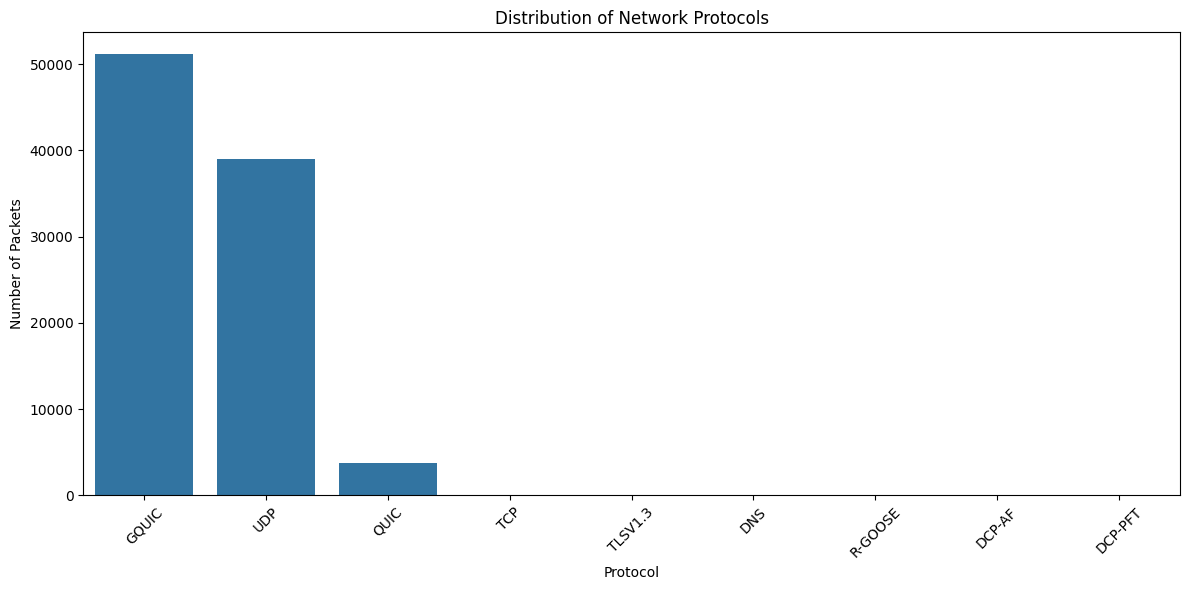

In [8]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Protocol",
    order=df["Protocol"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Distribution of Network Protocols")
plt.xlabel("Protocol")
plt.ylabel("Number of Packets")
plt.tight_layout()
plt.show()

In [9]:
print(df["Length"].describe())

count    94003.000000
mean      1037.794868
std        439.622915
min         40.000000
25%       1051.000000
50%       1278.000000
75%       1278.000000
max       4011.000000
Name: Length, dtype: float64


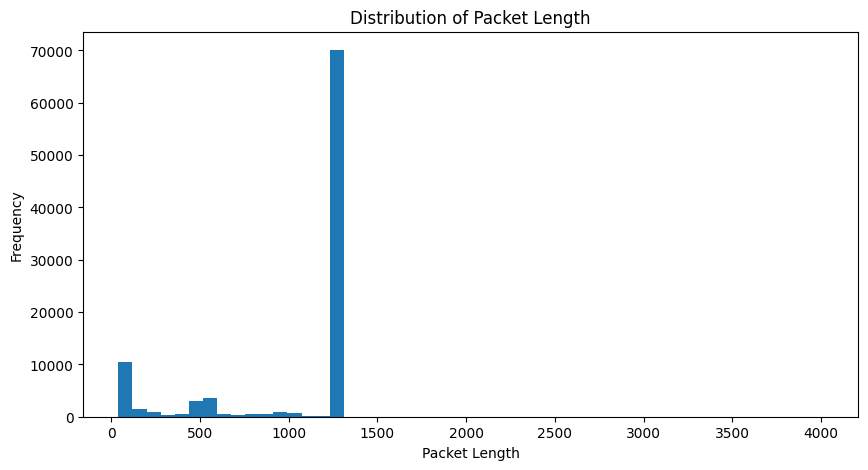

In [10]:
plt.figure(figsize=(10, 5))

plt.hist(df["Length"], bins=50)

plt.title("Distribution of Packet Length")
plt.xlabel("Packet Length")
plt.ylabel("Frequency")

plt.show()

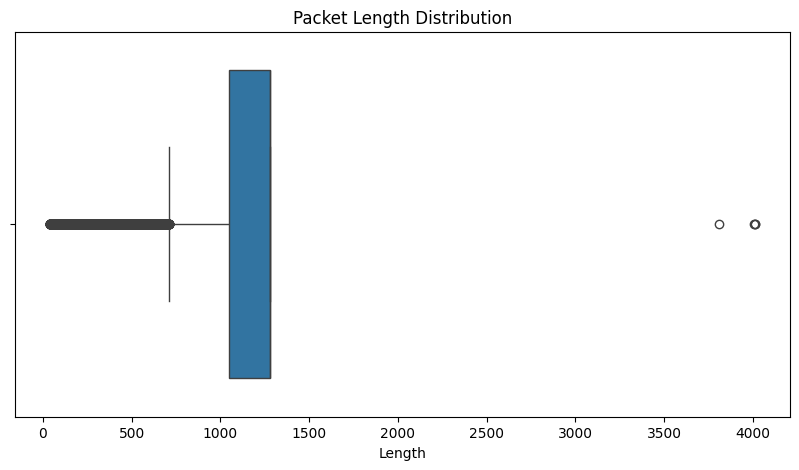

In [11]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Length"])

plt.title("Packet Length Distribution")
plt.xlabel("Length")

plt.show()

In [12]:
df["Time"] = pd.to_datetime(
    df["Time"],
    errors="coerce"
)

df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
df["Second"] = df["Time"].dt.second

# Older records without timestamps receive zero values
df[["Hour", "Minute", "Second"]] = (
    df[["Hour", "Minute", "Second"]].fillna(0)
)

df[["Time", "Length", "Hour", "Minute", "Second"]].head()

,Time,Length,Hour,Minute,Second
0,NaT,57.0,0.0,0.0,0.0
1,NaT,1278.0,0.0,0.0,0.0
2,2022-06-28 20:59:13.341304,1278.0,20.0,59.0,13.0
3,2022-06-28 17:35:24.905391,1278.0,17.0,35.0,24.0
4,NaT,1278.0,0.0,0.0,0.0


In [13]:
X = df[
    [
        "Length",
        "Hour",
        "Minute",
        "Second"
    ]
]

y = df["Protocol"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:


,Length,Hour,Minute,Second
0,57.0,0.0,0.0,0.0
1,1278.0,0.0,0.0,0.0
2,1278.0,20.0,59.0,13.0
3,1278.0,17.0,35.0,24.0
4,1278.0,0.0,0.0,0.0



Target:


,Protocol
0,GQUIC
1,GQUIC
2,UDP
3,UDP
4,GQUIC



X shape: (94003, 4)
y shape: (94003,)


In [14]:
protocol_counts = y.value_counts()

valid_protocols = protocol_counts[
    protocol_counts >= 20
].index

excluded_protocols = protocol_counts[
    protocol_counts < 20
]

print("Protocols excluded due to fewer than 20 records:")
print(excluded_protocols)

df = df[df["Protocol"].isin(valid_protocols)].copy()

X = df[
    ["Length", "Hour", "Minute", "Second"]
]

y = df["Protocol"]

print("\nFinal dataset shape:", df.shape)
print("\nFinal protocol distribution:")
print(y.value_counts())

Protocols excluded due to fewer than 20 records:
Protocol
DNS        12
R-GOOSE     6
DCP-AF      4
DCP-PFT     2
Name: count, dtype: int64

Final dataset shape: (93979, 9)

Final protocol distribution:
Protocol
GQUIC      51141
UDP        39032
QUIC        3745
TCP           32
TLSV1.3       29
Name: count, dtype: int64


In [15]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Protocol classes:")
print(label_encoder.classes_)

print("\nEncoded values:")
print(y_encoded[:20])

Protocol classes:
['GQUIC' 'QUIC' 'TCP' 'TLSV1.3' 'UDP']

Encoded values:
[0 0 4 4 0 0 0 4 1 4 0 0 0 0 0 4 4 0 0 0]


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 75183
Testing samples: 18796


In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [18]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = logistic_model.predict(X_test_scaled)

accuracy_lr = accuracy_score(
    y_test,
    y_pred_lr
)

print("Logistic Regression Accuracy:",
      accuracy_lr * 100, "%")

Logistic Regression Accuracy: 75.92040859757395 %


In [19]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(
    X_test_scaled
)

accuracy_knn = accuracy_score(
    y_test,
    y_pred_knn
)

print("KNN Accuracy:",
      accuracy_knn * 100, "%")

KNN Accuracy: 98.99446690785273 %


In [20]:
dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

dt_model.fit(
    X_train,
    y_train
)

y_pred_dt = dt_model.predict(X_test)

accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print("Decision Tree Accuracy:",
      accuracy_dt * 100, "%")

Decision Tree Accuracy: 98.73909342413279 %


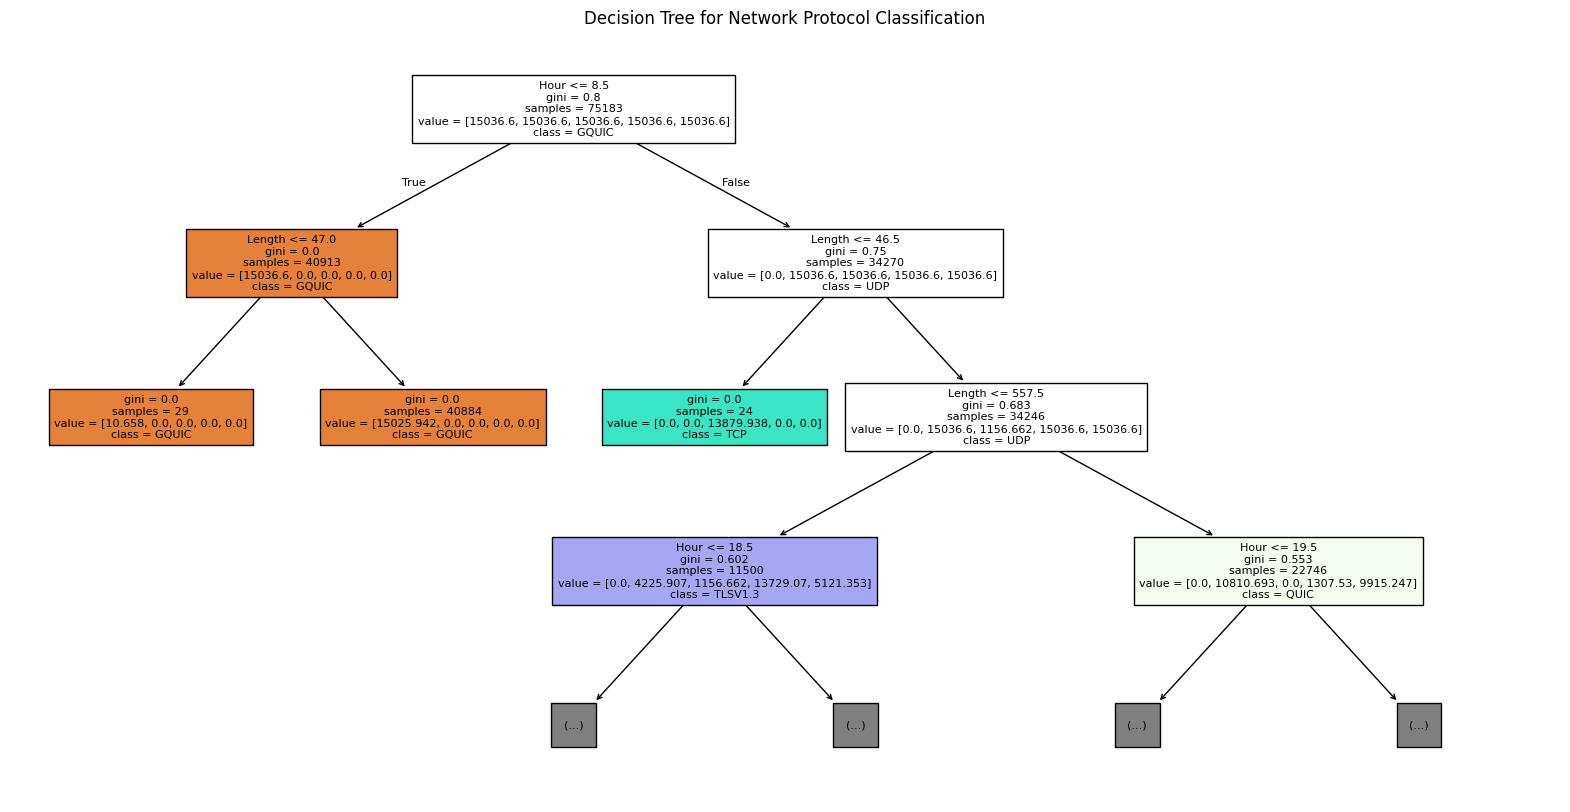

In [21]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=label_encoder.classes_,
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree for Network Protocol Classification")
plt.show()

In [22]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    max_depth=18,
    class_weight="balanced_subsample"
)

rf_model.fit(
    X_train,
    y_train
)

y_pred_rf = rf_model.predict(X_test)

accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print("Random Forest Accuracy:",
      accuracy_rf * 100, "%")

Random Forest Accuracy: 99.54777612257926 %


In [23]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_lr,
        accuracy_knn,
        accuracy_dt,
        accuracy_rf
    ]
})

results["Accuracy (%)"] = (
    results["Accuracy"] * 100
)

results["Balanced Accuracy (%)"] = [
    balanced_accuracy_score(y_test, y_pred_lr) * 100,
    balanced_accuracy_score(y_test, y_pred_knn) * 100,
    balanced_accuracy_score(y_test, y_pred_dt) * 100,
    balanced_accuracy_score(y_test, y_pred_rf) * 100
]

print("Model Comparison:")
display(results.sort_values(
    by="Accuracy (%)",
    ascending=False
))

Model Comparison:


,Model,Accuracy,Accuracy (%),Balanced Accuracy (%)
3,Random Forest,0.995478,99.547776,94.930626
1,KNN,0.989945,98.994467,59.207981
2,Decision Tree,0.987391,98.739093,98.499655
0,Logistic Regression,0.759204,75.920409,72.570357


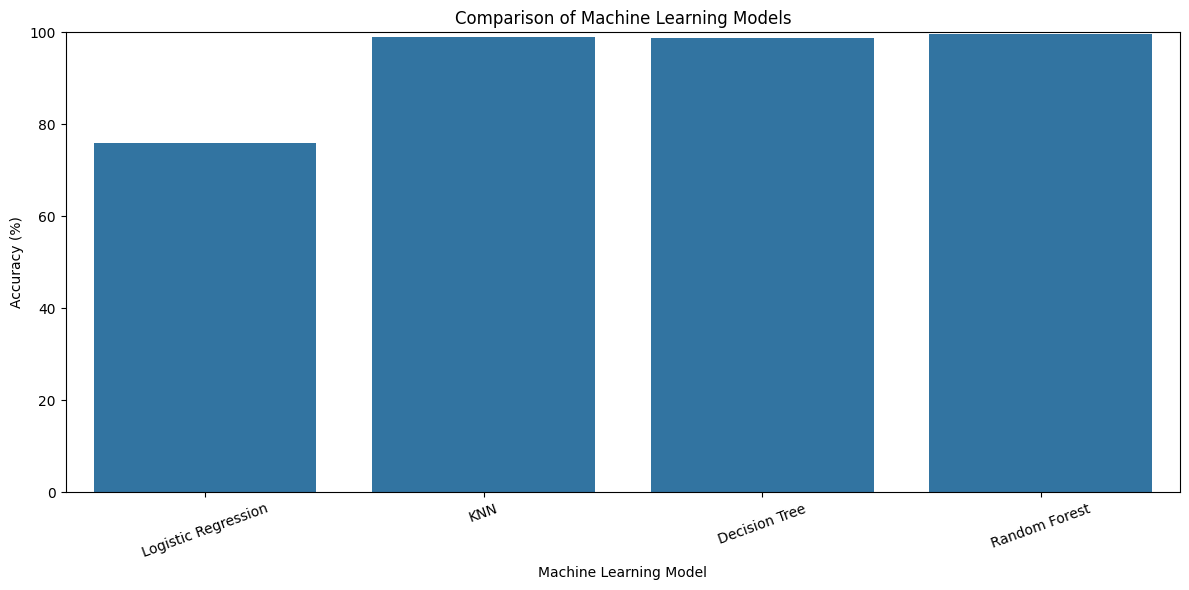

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.xticks(rotation=20)
plt.ylim(0, 100)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()

In [25]:
best_model_name = results.loc[
    results["Accuracy"].idxmax(),
    "Model"
]

print("Best Model:", best_model_name)

print(
    "Best Accuracy:",
    results["Accuracy"].max() * 100,
    "%"
)

Best Model: Random Forest
Best Accuracy: 99.54777612257926 %


In [26]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
display(feature_importance)

Feature Importance:


,Feature,Importance
0,Length,0.396533
1,Hour,0.301503
2,Minute,0.250379
3,Second,0.051585


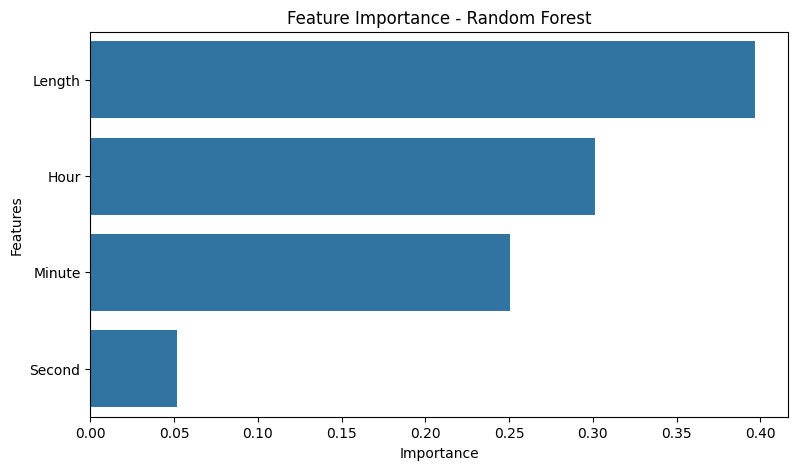

In [27]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

In [28]:
print("Random Forest Classification Report:")

print(
    classification_report(
        y_test,
        y_pred_rf,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Random Forest Classification Report:
              precision    recall  f1-score   support

       GQUIC       1.00      1.00      1.00     10228
        QUIC       0.97      0.92      0.94       749
         TCP       1.00      1.00      1.00         6
     TLSV1.3       1.00      0.83      0.91         6
         UDP       0.99      1.00      0.99      7807

    accuracy                           1.00     18796
   macro avg       0.99      0.95      0.97     18796
weighted avg       1.00      1.00      1.00     18796



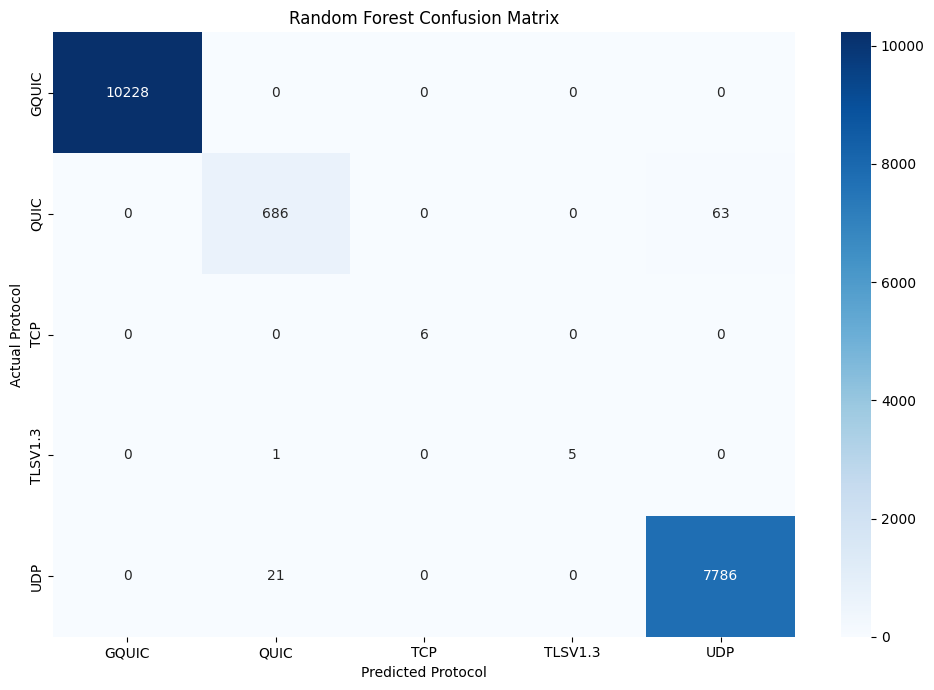

In [29]:
cm = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Protocol")
plt.ylabel("Actual Protocol")

plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()

In [30]:
new_packet = pd.DataFrame({
    "Length": [64],
    "Hour": [10],
    "Minute": [30],
    "Second": [15]
})

prediction = rf_model.predict(new_packet)

predicted_protocol = label_encoder.inverse_transform(
    prediction
)

print("New Packet Details:")
display(new_packet)

print("Predicted Protocol:",
      predicted_protocol[0])

New Packet Details:


,Length,Hour,Minute,Second
0,64,10,30,15


Predicted Protocol: QUIC


In [31]:
model_data = {
    "model": rf_model,
    "label_encoder": label_encoder,
    "features": list(X.columns)
}

joblib.dump(
    model_data,
    "network_protocol_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [32]:
# Save model comparison
results.to_csv(
    "model_comparison.csv",
    index=False
)

# Save feature importance
feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

# Save prediction results
prediction_results = pd.DataFrame({
    "Actual Protocol": label_encoder.inverse_transform(y_test),
    "Predicted Protocol": label_encoder.inverse_transform(y_pred_rf)
})

prediction_results.to_csv(
    "prediction_results.csv",
    index=False
)

# Download files
files.download("network_protocol_model.pkl")
files.download("model_comparison.csv")
files.download("feature_importance.csv")
files.download("prediction_results.csv")

print("All project files saved!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All project files saved!


In [33]:
print("=" * 60)
print("NETWORK PROTOCOL CLASSIFICATION USING MACHINE LEARNING")
print("=" * 60)

print("\nDataset Records:", len(df))

print("Number of Protocol Classes:",
      len(label_encoder.classes_))

print("\nMachine Learning Models:")
print("1. Logistic Regression")
print("2. K-Nearest Neighbors")
print("3. Decision Tree")
print("4. Random Forest")

print("\nBest Performing Model:", best_model_name)

print("\nBest Accuracy:",
      round(results["Accuracy"].max() * 100, 2), "%")

print("\nPROJECT COMPLETED SUCCESSFULLY!")

NETWORK PROTOCOL CLASSIFICATION USING MACHINE LEARNING

Dataset Records: 93979
Number of Protocol Classes: 5

Machine Learning Models:
1. Logistic Regression
2. K-Nearest Neighbors
3. Decision Tree
4. Random Forest

Best Performing Model: Random Forest

Best Accuracy: 99.55 %

PROJECT COMPLETED SUCCESSFULLY!
